# NIDS - Neural Network (MLP/DNN) Only Pipeline

Extracted from the full multi-model notebook, keeping **only** the steps required to train and use the Deep Feedforward Neural Network (MLP) on CICIDS2017-style tabular flow data.

**Two bugs from the original notebook are fixed here:**
1. Test set was being re-fit by `StandardScaler` instead of transformed with the scaler fit on training data (data leakage / inconsistent scaling).
2. `validation_split` was slicing the tail of the SMOTE-resampled, non-shuffled training data, producing a broken validation signal (train acc ~98% vs val acc ~20%). Fixed by shuffling the resampled data before Keras takes its validation slice.

## Step 0: Imports & Setup

In [2]:
import os
import time
import numpy as np
import pandas as pd
from collections import Counter

from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report, accuracy_score,
    precision_score, recall_score, f1_score
)
from sklearn.utils import shuffle

from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler
from imblearn.pipeline import Pipeline as ImbPipeline

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, BatchNormalization
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.utils import to_categorical

import joblib

np.random.seed(42)
tf.random.set_seed(42)

print(f"Tensorflow Version: {tf.__version__}")
print(f"GPU Available: {len(tf.config.list_physical_devices('GPU')) > 0}")

Tensorflow Version: 2.10.0
GPU Available: True


## Step 1: Load Data
Combine all CICIDS2017 CSV files into a single dataframe.

In [3]:
BASE_PATH = "./data/cicids2017"  # <-- adjust to your dataset path

csv_files = [f for f in os.listdir(BASE_PATH) if f.endswith(".csv")]
print(f"Found {len(csv_files)} CSV files.")

dfs = [pd.read_csv(os.path.join(BASE_PATH, f), encoding="utf-8") for f in csv_files]
df = pd.concat(dfs, ignore_index=True)

print(f"Total dataset shape: {df.shape}")
df.head()

Found 8 CSV files.
Total dataset shape: (2830743, 79)


,Destination Port,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,...,min_seg_size_forward,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label
0,54865,3,2,0,12,0,6,6,6.0,0.0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
1,55054,109,1,1,6,6,6,6,6.0,0.0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
2,55055,52,1,1,6,6,6,6,6.0,0.0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
3,46236,34,1,1,6,6,6,6,6.0,0.0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
4,54863,3,2,0,12,0,6,6,6.0,0.0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN


## Step 2: Clean Data
Strip column names, replace infinite values with NaN, and median-impute missing values.

In [4]:
df.columns = df.columns.str.strip()
label_col = "Label"

numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()

inf_count = np.isinf(df[numeric_cols]).sum().sum()
print(f"Found {inf_count:,} infinite values")
if inf_count > 0:
    df[numeric_cols] = df[numeric_cols].replace([np.inf, -np.inf], np.nan)

missing_before = df.isnull().sum().sum()
print(f"Missing values before imputation: {missing_before:,}")
for col in numeric_cols:
    if df[col].isnull().sum() > 0:
        df[col] = df[col].fillna(df[col].median())

print(f"Missing values after imputation: {df.isnull().sum().sum():,}")

Found 4,376 infinite values
Missing values before imputation: 5,734
Missing values after imputation: 0


## Step 3: Encode Labels & Select Features
Multi-class label encoding, then keep numeric feature columns only.

In [5]:
X = df.drop(columns=[label_col], errors="ignore")
y = df[label_col].copy()

le = LabelEncoder()
y_encoded = le.fit_transform(y)

X_numeric = X.select_dtypes(include=[np.number])
feature_names = X_numeric.columns.tolist()

print(f"Classes ({len(le.classes_)}): {list(le.classes_)}")
print(f"Feature matrix shape: {X_numeric.shape}")

Classes (15): ['BENIGN', 'Bot', 'DDoS', 'DoS GoldenEye', 'DoS Hulk', 'DoS Slowhttptest', 'DoS slowloris', 'FTP-Patator', 'Heartbleed', 'Infiltration', 'PortScan', 'SSH-Patator', 'Web Attack � Brute Force', 'Web Attack � Sql Injection', 'Web Attack � XSS']
Feature matrix shape: (2830743, 78)


## Step 4: Stratified Train/Test Split

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X_numeric, y_encoded,
    test_size=0.3,
    random_state=42,
    stratify=y_encoded,
)

print(f"Train: {X_train.shape[0]:,} samples | Test: {X_test.shape[0]:,} samples")

Train: 1,981,520 samples | Test: 849,223 samples


In [7]:
import json
import os

os.makedirs("models", exist_ok=True)

feature_columns = X_train.columns.tolist()
feature_medians = X_train.median().to_dict()

with open("models/feature_columns.json", "w") as f:
    json.dump(feature_columns, f, indent=2)

with open("models/feature_medians.json", "w") as f:
    json.dump(feature_medians, f, indent=2)

print(f"Saved: models/feature_columns.json  ({len(feature_columns)} columns, in training order)")
print(f"Saved: models/feature_medians.json  ({len(feature_medians)} medians)")


Saved: models/feature_columns.json  (78 columns, in training order)
Saved: models/feature_medians.json  (78 medians)


## Step 5: Feature Scaling
**Bug fixed:** the scaler is fit on the training data only, then reused with `.transform()` (not `.fit_transform()`) on the test data.

In [7]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)  # fixed: was fit_transform() in the original notebook

X_train_scaled = pd.DataFrame(X_train_scaled, columns=feature_names)
X_test_scaled = pd.DataFrame(X_test_scaled, columns=feature_names)

print("Feature scaling completed.")

Feature scaling completed.


## Step 6: Handle Class Imbalance (SMOTE + Random Under-sampling)
Rebalance the training data only. **Bug fixed:** the resampled data is shuffled afterward so that Keras's `validation_split` (a tail-slice) doesn't end up sampling mostly synthetic minority-class rows.

In [8]:
original_dist = Counter(y_train)
majority_class = max(original_dist, key=original_dist.get)
majority_count = original_dist[majority_class]
target_minority = int(majority_count * 0.1)

sampling_strategy_over = {
    cls: max(count, target_minority)
    for cls, count in original_dist.items()
    if cls != majority_class and count < target_minority
}
target_majority = int(target_minority * 5)
sampling_strategy_under = {majority_class: target_majority}

over = SMOTE(sampling_strategy=sampling_strategy_over, random_state=42)
under = RandomUnderSampler(sampling_strategy=sampling_strategy_under, random_state=42)
pipeline = ImbPipeline(steps=[("over", over), ("under", under)])

X_train_resampled, y_train_resampled = pipeline.fit_resample(X_train_scaled, y_train)

# Fixed: shuffle so a later validation_split isn't just synthetic minority-class rows
X_train_resampled, y_train_resampled = shuffle(X_train_resampled, y_train_resampled, random_state=42)

print(f"Resampled training size: {len(y_train_resampled):,}")

Resampled training size: 3,025,839


## Step 7: Build the MLP / DNN Architecture
256 → 128 → 64 → 32 → softmax, with BatchNorm + Dropout after every dense layer.

In [9]:
n_features = X_train_resampled.shape[1]
n_classes = len(np.unique(y_train_resampled))

nn_model = Sequential([
    Dense(256, activation="relu", input_shape=(n_features,)),
    BatchNormalization(),
    Dropout(0.3),

    Dense(128, activation="relu"),
    BatchNormalization(),
    Dropout(0.3),

    Dense(64, activation="relu"),
    BatchNormalization(),
    Dropout(0.2),

    Dense(32, activation="relu"),
    BatchNormalization(),
    Dropout(0.2),

    Dense(n_classes, activation="softmax"),
])

nn_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="categorical_crossentropy",
    metrics=["accuracy", keras.metrics.Precision(), keras.metrics.Recall()],
)

nn_model.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense (Dense)               (None, 256)               20224     
                                                                 
 batch_normalization (BatchN  (None, 256)              1024      
 ormalization)                                                   
                                                                 
 dropout (Dropout)           (None, 256)               0         
                                                                 
 dense_1 (Dense)             (None, 128)               32896     
                                                                 
 batch_normalization_1 (Batc  (None, 128)              512       
 hNormalization)                                                 
                                                                 
 dropout_1 (Dropout)         (None, 128)               0

## Step 8: Train the MLP
EarlyStopping + ReduceLROnPlateau, 30 epochs, batch size 512.

In [10]:
y_train_cat = to_categorical(y_train_resampled, num_classes=n_classes)

early_stop = EarlyStopping(
    monitor="val_loss", patience=5, restore_best_weights=True, verbose=1
)
reduce_lr = ReduceLROnPlateau(
    monitor="val_loss", factor=0.5, patience=3, min_lr=1e-5, verbose=1
)

start_time = time.time()
history = nn_model.fit(
    X_train_resampled, y_train_cat,
    epochs=30,
    batch_size=512,
    validation_split=0.2,  # safe now: data was shuffled in Step 6
    callbacks=[early_stop, reduce_lr],
    verbose=1,
)
print(f"Training time: {time.time() - start_time:.2f}s")
print(f"Epochs completed: {len(history.history['loss'])}")

Epoch 1/30
4728/4728 [==============================] - 58s 12ms/step - loss: 0.2695 - accuracy: 0.8940 - precision: 0.9142 - recall: 0.8744 - val_loss: 0.1547 - val_accuracy: 0.9235 - val_precision: 0.9275 - val_recall: 0.9188 - lr: 0.0010
Epoch 2/30
4728/4728 [==============================] - 55s 12ms/step - loss: 0.1715 - accuracy: 0.9232 - precision: 0.9287 - recall: 0.9172 - val_loss: 0.1488 - val_accuracy: 0.9269 - val_precision: 0.9277 - val_recall: 0.9261 - lr: 0.0010
Epoch 3/30
4728/4728 [==============================] - 54s 11ms/step - loss: 0.1601 - accuracy: 0.9273 - precision: 0.9320 - recall: 0.9220 - val_loss: 0.1418 - val_accuracy: 0.9363 - val_precision: 0.9374 - val_recall: 0.9352 - lr: 0.0010
Epoch 4/30
4728/4728 [==============================] - 55s 12ms/step - loss: 0.1535 - accuracy: 0.9299 - precision: 0.9342 - recall: 0.9251 - val_loss: 0.1368 - val_accuracy: 0.9373 - val_precision: 0.9411 - val_recall: 0.9326 - lr: 0.0010
Epoch 5/30
4728/4728 [==============

## Step 9: Evaluate on the Test Set

In [11]:
y_pred_proba = nn_model.predict(X_test_scaled, verbose=0)
y_pred = np.argmax(y_pred_proba, axis=1)

print(f"Accuracy:  {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision: {precision_score(y_test, y_pred, average='weighted', zero_division=0):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred, average='weighted', zero_division=0):.4f}")
print(f"F1-Score:  {f1_score(y_test, y_pred, average='weighted', zero_division=0):.4f}")

print(classification_report(y_test, y_pred, target_names=le.classes_, zero_division=0))

Accuracy:  0.9860
Precision: 0.9942
Recall:    0.9860
F1-Score:  0.9897
                            precision    recall  f1-score   support

                    BENIGN       1.00      0.98      0.99    681929
                       Bot       0.10      0.99      0.18       590
                      DDoS       1.00      1.00      1.00     38408
             DoS GoldenEye       0.95      1.00      0.97      3088
                  DoS Hulk       0.96      1.00      0.98     69322
          DoS Slowhttptest       0.86      0.99      0.92      1650
             DoS slowloris       0.97      0.99      0.98      1739
               FTP-Patator       0.99      1.00      1.00      2381
                Heartbleed       1.00      1.00      1.00         3
              Infiltration       0.29      0.64      0.40        11
                  PortScan       0.99      1.00      1.00     47679
               SSH-Patator       0.90      0.99      0.94      1769
  Web Attack � Brute Force       0.27      

### Plot training history

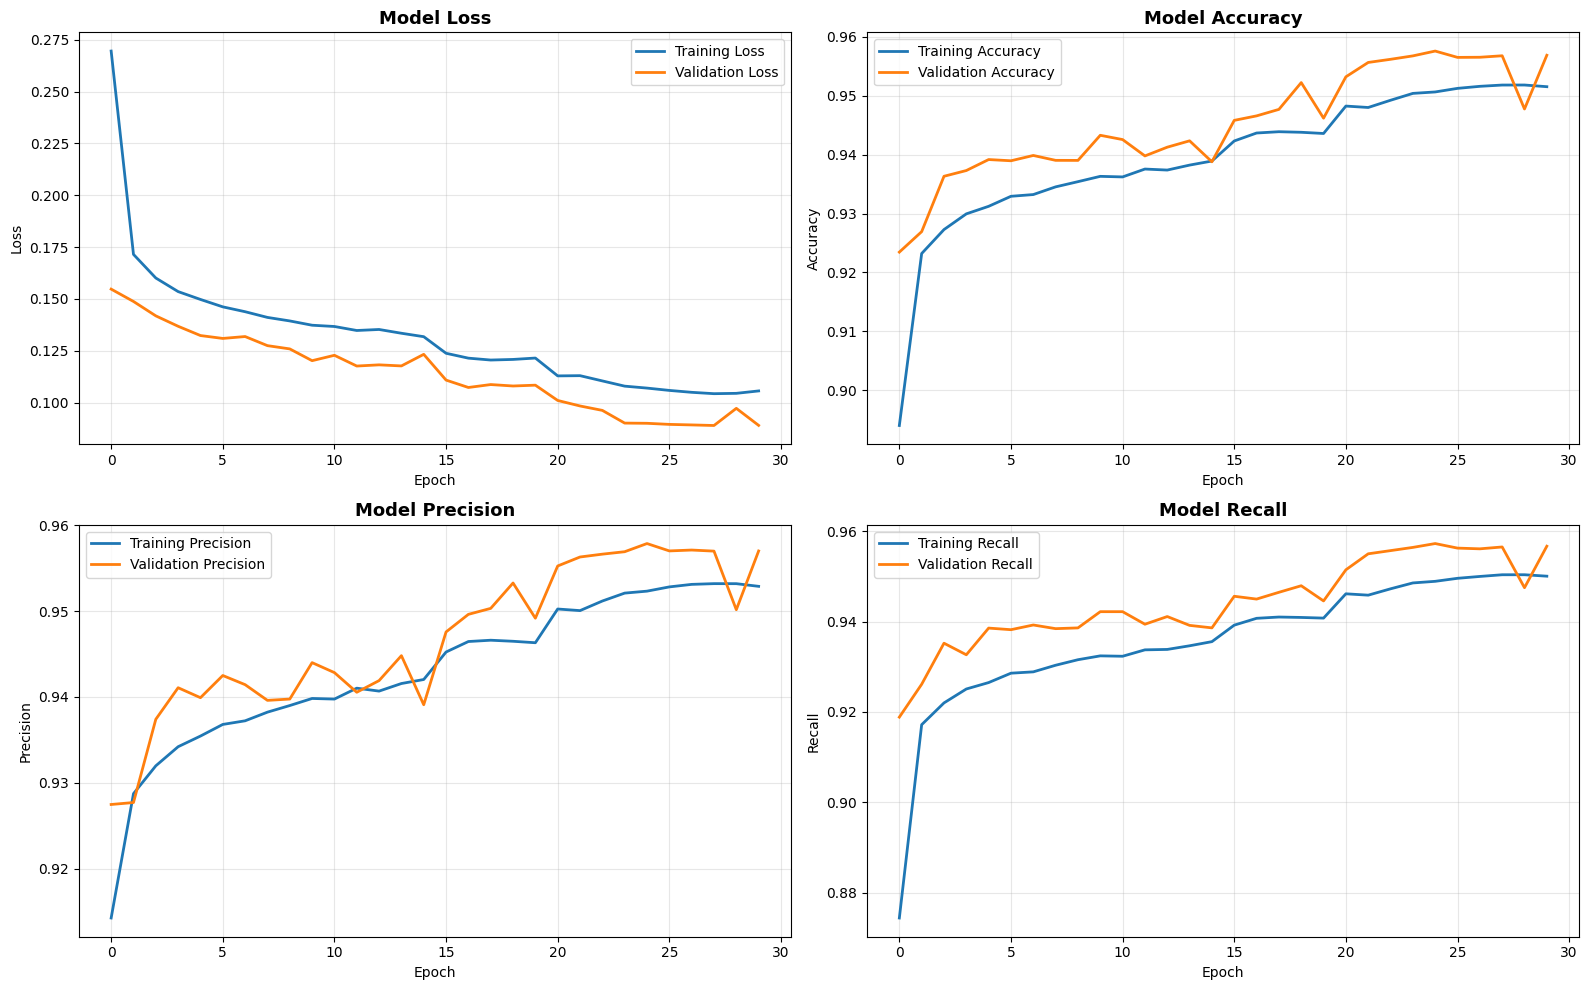

In [12]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(16, 10))

axes[0, 0].plot(history.history['loss'], label='Training Loss', linewidth=2)
axes[0, 0].plot(history.history['val_loss'], label='Validation Loss', linewidth=2)
axes[0, 0].set_title('Model Loss', fontsize=13, fontweight='bold')
axes[0, 0].set_xlabel('Epoch'); axes[0, 0].set_ylabel('Loss'); axes[0, 0].legend(); axes[0, 0].grid(alpha=0.3)

axes[0, 1].plot(history.history['accuracy'], label='Training Accuracy', linewidth=2)
axes[0, 1].plot(history.history['val_accuracy'], label='Validation Accuracy', linewidth=2)
axes[0, 1].set_title('Model Accuracy', fontsize=13, fontweight='bold')
axes[0, 1].set_xlabel('Epoch'); axes[0, 1].set_ylabel('Accuracy'); axes[0, 1].legend(); axes[0, 1].grid(alpha=0.3)

axes[1, 0].plot(history.history['precision'], label='Training Precision', linewidth=2)
axes[1, 0].plot(history.history['val_precision'], label='Validation Precision', linewidth=2)
axes[1, 0].set_title('Model Precision', fontsize=13, fontweight='bold')
axes[1, 0].set_xlabel('Epoch'); axes[1, 0].set_ylabel('Precision'); axes[1, 0].legend(); axes[1, 0].grid(alpha=0.3)

axes[1, 1].plot(history.history['recall'], label='Training Recall', linewidth=2)
axes[1, 1].plot(history.history['val_recall'], label='Validation Recall', linewidth=2)
axes[1, 1].set_title('Model Recall', fontsize=13, fontweight='bold')
axes[1, 1].set_xlabel('Epoch'); axes[1, 1].set_ylabel('Recall'); axes[1, 1].legend(); axes[1, 1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

## Step 10: Save Model + Preprocessing Artifacts
You need all three files together at inference time: the model, the scaler, and the label encoder.

In [13]:
os.makedirs("models", exist_ok=True)

nn_model.save("models/neural_network_ids.h5")
joblib.dump(scaler, "models/scaler.pkl")
joblib.dump(le, "models/label_encoder.pkl")

print("Saved: models/neural_network_ids.h5")
print("Saved: models/scaler.pkl")
print("Saved: models/label_encoder.pkl")

Saved: models/neural_network_ids.h5
Saved: models/scaler.pkl
Saved: models/label_encoder.pkl


## Summary

In [14]:
print(f"Total Samples: {len(df):,}")
print(f"Features: {len(feature_names)}")
print(f"Attack Types: {len(le.classes_)}")
print(f"Training Samples: {len(y_train):,}")
print(f"Test Samples: {len(y_test):,}")
print(f"Final Test F1-Score: {f1_score(y_test, y_pred, average='weighted', zero_division=0):.4f}")
print(f"Final Test Recall (Attack Detection): {recall_score(y_test, y_pred, average='weighted', zero_division=0):.4f}")

Total Samples: 2,830,743
Features: 78
Attack Types: 15
Training Samples: 1,981,520
Test Samples: 849,223
Final Test F1-Score: 0.9897
Final Test Recall (Attack Detection): 0.9860
